In [1]:
import os
import re
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

# Final cohort export from build_cohort notebook
EXP_NAME = "E8b_vascular_signal"
HORIZON_YEARS = 5
COHORT_PATH = os.path.join(OUT_DIR, f'cohort_{EXP_NAME}_H{HORIZON_YEARS}.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [2]:
df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [3]:
# NACC special-code cleanup + harmonization

df = df.copy()

# Replacing structural missing code -4 with NaN everywhere numeric
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].replace(-4, np.nan)

# Replacing common generic unknown codes
COMMON_UNKNOWN_CODES = {8, 9, 88, 99, 888, 999, 8888, 9999}

vars_to_soft_clean = [
    "DIABETES", "DIABET",
    "CVAFIB", "AFIBRILL",
    "APNEA", "SLEEPAP",
    "HYPERTEN", "HYPERT",
    "HYPERCHO", "HYPCHOL",
    "CBSTROKE", "CBTIA",
    "CVDSIGNS", "POSTINST",
    "NACCMMSE", "CDRSUM", "NACCAGE", "EDUC"
]

for col in vars_to_soft_clean:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(list(COMMON_UNKNOWN_CODES), np.nan)

# 3) Harmonize cross-version medical variables
def combine_binary_cols(df_in, cols, new_name):
    present = [c for c in cols if c in df_in.columns]
    if len(present) == 0:
        return df_in
    x = df_in[present].copy()
    # treating positive values as present, zeros as absent, NaN ignored
    x = x.apply(pd.to_numeric, errors="coerce")
    df_in[new_name] = np.where((x == 1).any(axis=1), 1,
                         np.where((x == 0).any(axis=1), 0, np.nan))
    return df_in

df = combine_binary_cols(df, ["DIABETES", "DIABET"], "diabetes_any")
df = combine_binary_cols(df, ["CVAFIB", "AFIBRILL"], "afib_any")
df = combine_binary_cols(df, ["APNEA", "SLEEPAP"], "sleep_apnea_any")
df = combine_binary_cols(df, ["HYPERTEN", "HYPERT"], "htn_any")
df = combine_binary_cols(df, ["HYPERCHO", "HYPCHOL"], "hyperchol_any")

print("Harmonized columns created:")
for c in ["diabetes_any", "afib_any", "sleep_apnea_any", "htn_any", "hyperchol_any"]:
    if c in df.columns:
        print(c, df[c].value_counts(dropna=False).to_dict())

Harmonized columns created:
diabetes_any {0.0: 178333, 1.0: 16658, nan: 12463}
afib_any {0.0: 188667, 1.0: 15001, nan: 3786}
sleep_apnea_any {nan: 106691, 0.0: 80049, 1.0: 20714}
htn_any {1.0: 104806, 0.0: 96524, nan: 6124}
hyperchol_any {1.0: 109121, 0.0: 89653, nan: 8680}


C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has 

In [4]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\2428668717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [5]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
# if 'NACCUDSD' in post.columns:
#     dem_events_all = post[post['NACCUDSD'] == 4].copy()
#     dementia_def = 'NACCUDSD==4'
# else:
#     dem_events_all = post[post['DEMENTED'] == 1].copy()
#     dementia_def = 'DEMENTED==1'

def get_dementia_events(df_in):
    if "DEMENTED" in df_in.columns:
        return df_in[df_in["DEMENTED"] == 1].copy(), "DEMENTED==1"
    elif "NACCUDSD" in df_in.columns:
        return df_in[df_in["NACCUDSD"] == 4].copy(), "NACCUDSD==4"
    else:
        raise KeyError("Neither DEMENTED nor NACCUDSD found.")
    

dem_events_all, dementia_def = get_dementia_events(post)
first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474

=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: DEMENTED==1
Participants with ANY post-baseline dementia event: 5502


C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\2108224931.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [6]:
# def subtype_primary(row):
#     # Alzheimer's disease
#     if "NACCALZD" in row and row["NACCALZD"] == 1:
#         return "AD"

#     # Lewy body disease
#     if "NACCLBDE" in row and row["NACCLBDE"] == 1:
#         return "PD_LBD"

#     # Vascular brain injury
#     if "CVD" in row and row["CVD"] == 1:
#         return "Vascular"

#     return "Other/Unk"


# def subtype_anymention(row):
#     if ("NACCALZD" in row and row["NACCALZD"] == 1):
#         return "AD"

#     if ("NACCLBDE" in row and row["NACCLBDE"] == 1):
#         return "PD_LBD"

#     if ("CVD" in row and row["CVD"] == 1):
#         return "Vascular"

#     return "Other/Unk"


# def subtype_contributing(row):
#     if "NACCALZP" in row and row["NACCALZP"] in [1,2]:
#         return "AD"

#     if "NACCLBDP" in row and row["NACCLBDP"] in [1,2]:
#         return "PD_LBD"

#     if "CVDIF" in row and row["CVDIF"] in [1,2]:
#         return "Vascular"

#     return "Other/Unk"

In [7]:
# first_dem_ever["subtype_primary"] = first_dem_ever.apply(subtype_primary, axis=1)
# first_dem_ever["subtype_any"]     = first_dem_ever.apply(subtype_anymention, axis=1)
# first_dem_ever["subtype_contrib"] = first_dem_ever.apply(subtype_contributing, axis=1)

# first_dem_ever["subtype_primary_contrib"] = np.where(
#     first_dem_ever["subtype_primary"].eq("Other/Unk"),
#     first_dem_ever["subtype_contrib"],
#     first_dem_ever["subtype_primary"],
# )

# first_dem_ever["subtype_primary_contrib_any"] = np.where(
#     first_dem_ever["subtype_primary_contrib"].eq("Other/Unk"),
#     first_dem_ever["subtype_any"],
#     first_dem_ever["subtype_primary_contrib"],
# )

In [8]:
def subtype_primary(row):

    formver = row.get("FORMVER", np.nan)

    # PD / LBD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 2:
        return "PD_LBD"

    # Vascular
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 8:
        return "Vascular"

    # AD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 1:
        return "AD"

    return "Other/Unk"


# Stage 1: Primary
first_dem_ever["subtype_primary_contrib_any"] = first_dem_ever.apply(subtype_primary, axis=1)


print("\nFinal (Primary -> Contrib -> Any) subtype counts:")
display(first_dem_ever["subtype_primary_contrib_any"].value_counts())


Final (Primary -> Contrib -> Any) subtype counts:


subtype_primary_contrib_any
AD           4218
Other/Unk     651
PD_LBD        374
Vascular      259
Name: count, dtype: int64

In [9]:

# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4218
Other/Unk      651
PD_LBD         374
Vascular       259
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [10]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27052
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_any_dementia
0    22201
1     4851
Name: count, dtype: int64


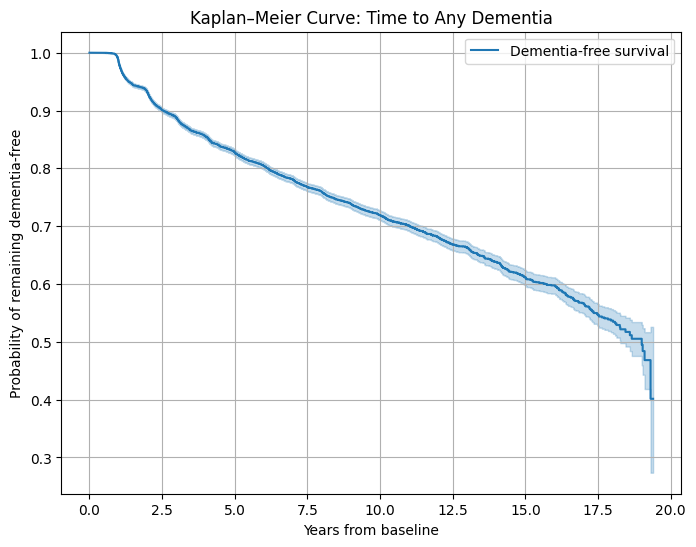

In [11]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
plt.show()

In [12]:
# Load final exported cohort features from build_cohort notebook

cohort_final = pd.read_csv(COHORT_PATH, low_memory=False)
cohort_final["NACCID"] = cohort_final["NACCID"].astype(str)

print("Loaded final cohort file:", COHORT_PATH)
print("cohort_final shape:", cohort_final.shape)
display(cohort_final.head(3))

Loaded final cohort file: ..\output\cohort_E8b_vascular_signal_H5.csv
cohort_final shape: (38341, 79)


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,EDUC,NACCUDSD,NACCMMSE,NACCMOCA,TRAILA,TRAILB,ANIMALS,BOSTON,CDRSUM,CDRGLOB,NACCMMSE_missing,NACCMOCA_missing,TRAILA_missing,TRAILB_missing,CDRSUM_missing,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,RESTTRL,RESTTRR,RIGIDL,RIGIDR,SLOWINGL,SLOWINGR,PARKGAIT,GAITDIS,DIABETES,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,CVCHF,CVANGINA,CVBYPASS,CVANGIO,CVHVALVE,CVOTHR,APNEA,DEP2YRS,DIABET,POSTINST,NACCGDS,DIGBACCT,DIGBACLS,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,STROKE_x_EXEC,STROKDEC,STROKMUL,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,16.0,3.0,30.0,NaN,32.0,76.0,20.0,27.0,0.5,0.5,0,1,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,-0.5,-0.0,NaN,NaN,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,15.0,3.0,NaN,27.0,52.0,155.0,15.0,NaN,0.5,0.5,1,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2.0,0,0.0,-0.5,-0.0,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,18.0,3.0,29.0,NaN,47.0,105.0,21.0,29.0,0.5,0.0,0,1,0,0,0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,1.0,NaN,NaN,13.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,-0.5,-0.0,NaN,NaN,1.0,0.0,NaN


In [13]:
# Exact final E8b feature list from build_cohort

E8B_FEATURES = [
    # Demographic
    "NACCAGE","SEX","RACE","HISPANIC","EDUC","NACCUDSD",

    # Cognitive / function
    "NACCMMSE","NACCMOCA","TRAILA","TRAILB","ANIMALS","BOSTON",
    "CDRSUM","CDRGLOB",
    "NACCMMSE_missing","NACCMOCA_missing","TRAILA_missing","TRAILB_missing","CDRSUM_missing",

    # Motor / PD-LBD
    "COGFLUC","BEVHALL","BEREM",
    "PARKSIGN","BRADY","RESTTRL","RESTTRR","RIGIDL","RIGIDR",
    "SLOWINGL","SLOWINGR","PARKGAIT","GAITDIS",

    # Medical / vascular / selected extras used in E8b
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB","CBSTROKE","CBTIA",
    "CVCHF","CVANGINA","CVBYPASS","CVANGIO","CVHVALVE","CVOTHR",
    "APNEA","DEP2YRS",
    "DIABET","POSTINST","NACCGDS","DIGBACCT","DIGBACLS",
    "CVD","VASC","CVDCOG","CVDIMAG","IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN","HACHIN",
    "HACHIN_GE_4","HACHIN_GE_7",
    "STROKE_TIA_ANY","VASC_MED_COUNT","GAIT_ANY",
    "CDR_ADL_COG_RATIO","CDR_ADL_MINUS_COG",
    "STROKE_x_EXEC","STROKDEC","STROKMUL",

    # Family / imaging extra
    "NACCMOM","NACCDAD","SIVDFIND"
]

base_cols_needed = ["NACCID", "label", "max_follow_years", "has_H_followup", "has_dementia_H"]

present_e8b = [c for c in E8B_FEATURES if c in cohort_final.columns]
missing_e8b = [c for c in E8B_FEATURES if c not in cohort_final.columns]

print("Present E8b features:", len(present_e8b))
print("Missing E8b features:", len(missing_e8b))
print("Missing:", missing_e8b)

cohort_features = cohort_final[["NACCID"] + present_e8b].copy()
print("cohort_features shape:", cohort_features.shape)

Present E8b features: 73
Missing E8b features: 0
Missing: []
cohort_features shape: (38341, 74)


In [14]:
# Merge final E8b feature export onto survival outcome dataframe

cox_df = surv_main.merge(cohort_features, on="NACCID", how="left")

# Recompute binary event just to be safe
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

print("Rows after merge:", len(cox_df))
print("Merged columns:", len(cox_df.columns))
display(cox_df.head(3))

Rows after merge: 27052
Merged columns: 83


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,RACE,HISPANIC,EDUC,NACCUDSD,NACCMMSE,NACCMOCA,TRAILA,TRAILB,ANIMALS,BOSTON,CDRSUM,CDRGLOB,NACCMMSE_missing,NACCMOCA_missing,TRAILA_missing,TRAILB_missing,CDRSUM_missing,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,RESTTRL,RESTTRR,RIGIDL,RIGIDR,SLOWINGL,SLOWINGR,PARKGAIT,GAITDIS,DIABETES,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,CVCHF,CVANGINA,CVBYPASS,CVANGIO,CVHVALVE,CVOTHR,APNEA,DEP2YRS,DIABET,POSTINST,NACCGDS,DIGBACCT,DIGBACLS,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,STROKE_x_EXEC,STROKDEC,STROKMUL,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62.0,2.0,1.0,0.0,16.0,3.0,30.0,NaN,32.0,76.0,20.0,27.0,0.5,0.5,0,1,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,-0.5,-0.0,NaN,NaN,NaN,NaN,NaN
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79.0,2.0,1.0,0.0,15.0,3.0,NaN,27.0,52.0,155.0,15.0,NaN,0.5,0.5,1,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2.0,0,0.0,-0.5,-0.0,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60.0,1.0,1.0,0.0,18.0,3.0,29.0,NaN,47.0,105.0,21.0,29.0,0.5,0.0,0,1,0,0,0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,1.0,NaN,NaN,13.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,-0.5,-0.0,NaN,NaN,1.0,0.0,NaN


In [15]:
# Survival-aligned modeling subsets
# These are ALL drawn only from the final E8b feature export.

SURVIVAL_CORE_FEATURES = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","CDRGLOB",
    "DEP2YRS","NACCGDS",

    "DIABETES","DIABET","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","CVDCOG","CVDIMAG",
    "IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN","HACHIN","HACHIN_GE_4","HACHIN_GE_7",
    "POSTINST","VASC_MED_COUNT","GAIT_ANY",
    "STROKDEC","STROKMUL","STROKE_x_EXEC",

    "TRAILA","TRAILB","DIGBACCT","DIGBACLS",
    "CDR_ADL_COG_RATIO","CDR_ADL_MINUS_COG",

    "COGFLUC","BEVHALL","BEREM","PARKSIGN","BRADY","PARKGAIT","GAITDIS",

    "NACCMOM","NACCDAD","SIVDFIND"
]

ANY_DEMENTIA_FEATURES = [c for c in SURVIVAL_CORE_FEATURES if c in cox_df.columns]

CAUSE_SPECIFIC_FEATURES = [c for c in SURVIVAL_CORE_FEATURES if c in cox_df.columns]

print("ANY_DEMENTIA_FEATURES:", ANY_DEMENTIA_FEATURES)

ANY_DEMENTIA_FEATURES: ['NACCAGE', 'SEX', 'EDUC', 'NACCMMSE', 'CDRSUM', 'CDRGLOB', 'DEP2YRS', 'NACCGDS', 'DIABETES', 'DIABET', 'HYPERTEN', 'HYPERCHO', 'CVAFIB', 'CBSTROKE', 'CBTIA', 'STROKE_TIA_ANY', 'CVD', 'VASC', 'CVDCOG', 'CVDIMAG', 'IMAGMWMH', 'IMAGEWMH', 'FOCLSYM', 'FOCLSIGN', 'HACHIN', 'HACHIN_GE_4', 'HACHIN_GE_7', 'POSTINST', 'VASC_MED_COUNT', 'GAIT_ANY', 'STROKDEC', 'STROKMUL', 'STROKE_x_EXEC', 'TRAILA', 'TRAILB', 'DIGBACCT', 'DIGBACLS', 'CDR_ADL_COG_RATIO', 'CDR_ADL_MINUS_COG', 'COGFLUC', 'BEVHALL', 'BEREM', 'PARKSIGN', 'BRADY', 'PARKGAIT', 'GAITDIS', 'NACCMOM', 'NACCDAD', 'SIVDFIND']


In [16]:
# Build Cox dataframe from aligned E8b features

model_cols = ["time_to_event", "event_any_dementia"] + ANY_DEMENTIA_FEATURES
cox_df_model = cox_df[model_cols].copy()

print("cox_df_model shape:", cox_df_model.shape)
display(cox_df_model.head(3))

cox_df_model shape: (27052, 51)


,time_to_event,event_any_dementia,NACCAGE,SEX,EDUC,NACCMMSE,CDRSUM,CDRGLOB,DEP2YRS,NACCGDS,DIABETES,DIABET,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,STROKE_TIA_ANY,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,POSTINST,VASC_MED_COUNT,GAIT_ANY,STROKDEC,STROKMUL,STROKE_x_EXEC,TRAILA,TRAILB,DIGBACCT,DIGBACLS,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,PARKGAIT,GAITDIS,NACCMOM,NACCDAD,SIVDFIND
0,3.296372,0,62.0,2.0,16.0,30.0,0.5,0.5,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0,NaN,NaN,-0.0,32.0,76.0,NaN,NaN,0.0,-0.5,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
1,5.848049,1,79.0,2.0,15.0,NaN,0.5,0.5,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,2.0,0,0.0,0.0,-0.0,52.0,155.0,5.0,4.0,0.0,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,0.0
2,2.088980,0,60.0,1.0,18.0,29.0,0.5,0.0,1.0,13.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1,NaN,NaN,-0.0,47.0,105.0,NaN,NaN,0.0,-0.5,0.0,0.0,1.0,NaN,NaN,NaN,1.0,1.0,0.0,NaN


In [17]:
# Missing-value handling

for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue

    cox_df_model[col] = pd.to_numeric(cox_df_model[col], errors="coerce")

    if cox_df_model[col].notna().sum() == 0:
        cox_df_model[col] = 0
    else:
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())

In [18]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))
print("Final Cox columns:", len(cox_df_model.columns))

Final Cox rows: 27052
Final Cox columns: 51


In [19]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27052 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27052
number of events observed = 4851
   partial log-likelihood = -42413.19
         time fit was run = 2026-03-14 04:51:14 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
NACCAGE            0.03      1.03      0.00            0.03            0.03                1.03                1.03
SEX               -0.08      0.93      0.02           -0.12           -0.03                0.88                0.97
EDUC               0.01      1.01      0.00            0.00            0.01                1.00                1.01
NACCMMSE          -0.13      0.88      0.01           -0.14           -0.12                0.87                0.89
CDRSUM             0.25      1.28      0.01            0.22            0.27                1.25                1.31
CDRGLOB            0.96      2.62      0.05            0.86            1.07                2.35                2.91
DEP2YRS            0.10      1.11      0.03            0.05            0.16                1.05                1.17
NACCGDS            0.02      1.02      0.01            0.01            0.03                1.01                1.03
DIABETES          -0.07      0.93      0.03           -0.14           -0.01                0.87                0.99
DIABET            -0.02      0.98      0.03           -0.08            0.04                0.92                1.04
HYPERTEN          -0.01      0.99      0.02           -0.06            0.03                0.94                1.03
HYPERCHO           0.01      1.01      0.02           -0.04            0.05                0.97                1.05
CVAFIB             0.09      1.09      0.03            0.02            0.15                1.02                1.17
CBSTROKE           0.06      1.06      0.04           -0.02            0.14                0.98                1.15
CBTIA              0.03      1.03      0.04           -0.04            0.10                0.96                1.11
STROKE_TIA_ANY     0.05      1.05      0.06           -0.06            0.16                0.94                1.18
CVD                0.05      1.05      0.08           -0.10            0.20                0.90                1.23
VASC               0.10      1.11      0.14           -0.16            0.37                0.85                1.45
CVDCOG            -0.25      0.78      0.10           -0.44           -0.06                0.64                0.94
CVDIMAG            0.31      1.36      0.12            0.07            0.55                1.07                1.74
IMAGMWMH           0.08      1.09      0.08           -0.08            0.25                0.92                1.28
IMAGEWMH          -0.01      0.99      0.20           -0.41            0.38                0.66                1.46
FOCLSYM           -0.05      0.95      0.09           -0.23            0.13                0.79                1.14
FOCLSIGN           0.04      1.05      0.07           -0.10            0.19                0.91                1.21
HACHIN            -0.01      0.99      0.02           -0.04            0.02                0.96                1.03
HACHIN_GE_4        0.06      1.06      0.09           -0.13            0.24                0.88                1.27
HACHIN_GE_7       -0.23      0.79      0.15           -0.52            0.06                0.59                1.06
POSTINST           0.28      1.32      0.14            0.00            0.55                1.00                1.73
VASC_MED_COUNT     0.00      1.00      0.01           -0.02         

In [20]:
# PH-friendlier model

cox_df_model2 = cox_df_model.copy()

# adding nonlinear age term
if "NACCAGE" in cox_df_model2.columns:
    cox_df_model2["NACCAGE_sq"] = cox_df_model2["NACCAGE"] ** 2

# stratifying by SEX
main_strata = ["SEX"] if "SEX" in cox_df_model2.columns else None

cox_ph2 = CoxPHFitter(penalizer=0.1)
cox_ph2.fit(
    cox_df_model2,
    duration_col="time_to_event",
    event_col="event_any_dementia",
    strata=main_strata
)

print("PH-friendlier model")
cox_ph2.print_summary()

PH-friendlier model


model,lifelines.CoxPHFitter
duration col,'time_to_event'
event col,'event_any_dementia'
penalizer,0.1
l1 ratio,0.0
strata,SEX
baseline estimation,breslow
number of observations,27052
number of events observed,4851
partial log-likelihood,-38984.72
time fit was run,2026-03-14 04:51:17 UTC


In [21]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDR_ADL_MINUS_COG,-0.559882,0.571277,0.022664,9.908246e-135
NACCAGE,0.030961,1.031445,0.001290,2.375676e-127
NACCMMSE,-0.130839,0.877359,0.005806,1.927886e-112
CDRSUM,0.245645,1.278446,0.011242,7.639638e-106
CDRGLOB,0.962851,2.619152,0.054256,1.835560e-70
CDR_ADL_COG_RATIO,0.551472,1.735806,0.033600,1.547844e-60
TRAILB,0.000494,1.000494,0.000059,9.769260e-17
DIGBACCT,-0.050845,0.950426,0.010830,2.665861e-06
COGFLUC,0.390626,1.477906,0.085983,5.544776e-06


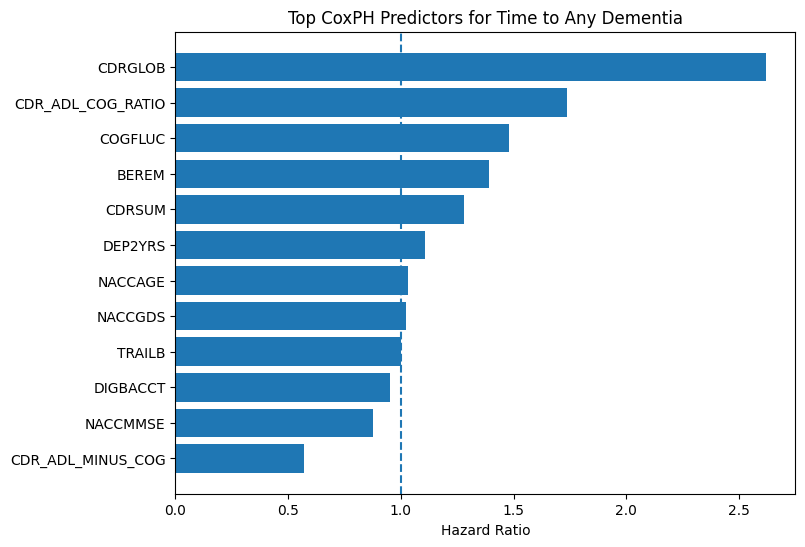

In [22]:
import matplotlib.pyplot as plt

top_hr = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

plt.figure(figsize=(8,6))
plt.barh(top_hr.index.astype(str), top_hr["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
plt.show()

In [23]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'SEX' failed the non-proportional test: p-value is 0.0490.

   Advice: with so few unique values (only 2), you can include `strata=['SEX', ...]` in the call in
`.fit`. See documentation in link [E] below.

3. Variable 'CDRGLOB' failed the non-proportional test: p-value is 0.0100.

   Advice 1: the functional form of the variable 'CDRGLOB' might

[]

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter, AalenJohansenFitter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [25]:
# master modeling dataframe

# Starting from cox_df (already merged with baseline features)
model_df = cox_df.copy()

# Binary event
model_df["event_any_dementia"] = (model_df["event_type"] != "Censored").astype(int)

# Keeping only rows with valid time
model_df = model_df[
    model_df["time_to_event"].notna() &
    (model_df["time_to_event"] > 0)
].copy()

print("model_df shape:", model_df.shape)
print(model_df["event_type"].value_counts(dropna=False))

model_df shape: (27052, 83)
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64


1) competing risks
Cell below — Numeric code for competing events

In [26]:
# competing risk event coding:
# 0 = censored
# 1 = AD
# 2 = PD_LBD
# 3 = Vascular

event_code_map = {
    "Censored": 0,
    "AD": 1,
    "PD_LBD": 2,
    "Vascular": 3
}

cr_df = model_df[model_df["event_type"].isin(event_code_map.keys())].copy()
cr_df["event_code"] = cr_df["event_type"].map(event_code_map).astype(int)

print(cr_df["event_type"].value_counts())
print(cr_df["event_code"].value_counts())

event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_code
0    22201
1     4218
2      374
3      259
Name: count, dtype: int64


Cell below — Cumulative incidence curves (Aalen-Johansen)


c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


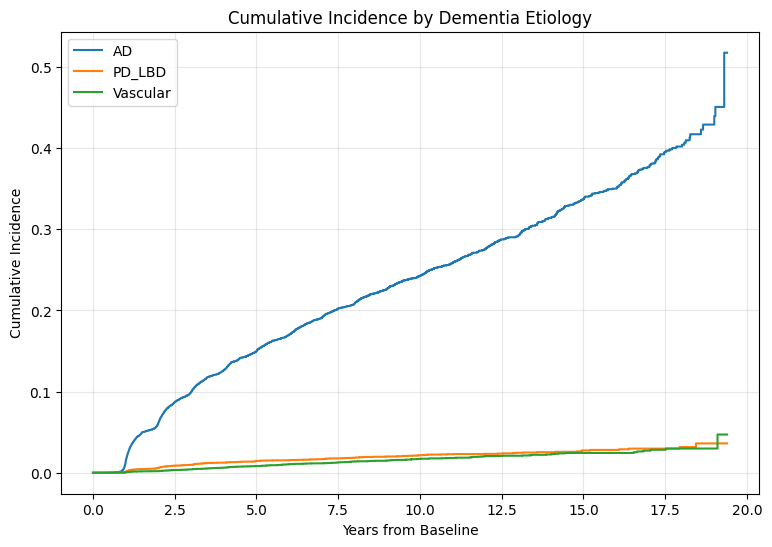

In [27]:
# cumulative incidence curves for competing risks

plt.figure(figsize=(9, 6))

for event_name, event_code in [("AD", 1), ("PD_LBD", 2), ("Vascular", 3)]:
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )
    ajf.plot(ci_show=False)

plt.title("Cumulative Incidence by Dementia Etiology")
plt.xlabel("Years from Baseline")
plt.ylabel("Cumulative Incidence")
plt.grid(True, alpha=0.3)
plt.legend(["AD", "PD_LBD", "Vascular"])
plt.show()

# Milestone cumulative incidence table

In [28]:
# Competing-risk cumulative incidence milestone table

milestone_years = [5, 10, 15]
event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

aj_tables = {}

for event_name, event_code in event_map.items():
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )

    cif_vals = []
    for yr in milestone_years:
        # nearest available timepoint
        idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
        cif_val = float(ajf.cumulative_density_.iloc[idx, 0])
        cif_vals.append(cif_val)

    aj_tables[event_name] = cif_vals

cif_milestone_table = pd.DataFrame(aj_tables, index=milestone_years)
cif_milestone_table.index.name = "Years"
display(cif_milestone_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


,AD,PD_LBD,Vascular
Years,,,
5,0.149811,0.014208,0.008154
10,0.242770,0.021564,0.017067
15,0.336780,0.027464,0.024370


2) cause-specific cox model
Cell below — helps to fit cause-specific Cox

In [29]:
# cause-specific cox helper

def fit_cause_specific_cox(df, event_name, features, penalizer=0.1):
    tmp = df.copy()
    tmp["event_cs"] = (tmp["event_type"] == event_name).astype(int)

    use_cols = ["time_to_event", "event_cs"] + [c for c in features if c in tmp.columns]
    tmp = tmp[use_cols].copy()

    for col in tmp.columns:
        if col in ["time_to_event", "event_cs"]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    # one-hot encoding categorical
    cat_cols = [c for c in tmp.columns if c not in ["time_to_event", "event_cs"] and not pd.api.types.is_numeric_dtype(tmp[c])]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(tmp, duration_col="time_to_event", event_col="event_cs")
    return cph, tmp

Cell below — Running cause-specific Cox for AD / PD_LBD / Vascular

In [30]:
# cause-specific cox models using aligned E8b features

cause_features = [c for c in CAUSE_SPECIFIC_FEATURES if c in model_df.columns]

cause_models = {}
cause_dfs = {}

for outcome in ["AD", "PD_LBD", "Vascular"]:
    cph, tmp_df = fit_cause_specific_cox(model_df, outcome, cause_features, penalizer=0.1)
    cause_models[outcome] = cph
    cause_dfs[outcome] = tmp_df

    print("\n" + "=" * 70)
    print(f"CAUSE-SPECIFIC COX FOR: {outcome}")
    print("=" * 70)
    display(
        cph.summary[["coef", "exp(coef)", "se(coef)", "p"]]
        .sort_values("p")
        .head(15)
    )


CAUSE-SPECIFIC COX FOR: AD


,coef,exp(coef),se(coef),p
covariate,,,,
CDR_ADL_MINUS_COG,-0.581316,0.559162,0.023563,2.235130e-134
NACCAGE,0.029609,1.030051,0.001336,7.808868e-109
NACCMMSE,-0.132284,0.876093,0.006045,3.618336e-106
CDRSUM,0.250042,1.284080,0.011527,2.493350e-104
CDRGLOB,0.951467,2.589506,0.055460,5.667967e-66
CDR_ADL_COG_RATIO,0.549403,1.732219,0.036258,7.300006e-52
TRAILB,0.000400,1.000400,0.000063,1.614205e-10
DIGBACCT,-0.045404,0.955611,0.011021,3.795031e-05
NACCMOM,0.084437,1.088105,0.025475,9.178902e-04



CAUSE-SPECIFIC COX FOR: PD_LBD


,coef,exp(coef),se(coef),p
covariate,,,,
BEREM,2.576386,13.149533,0.116081,3.862386e-109
BEVHALL,3.585070,36.055871,0.176531,1.081734e-91
COGFLUC,2.401400,11.038621,0.127829,9.824926e-79
PARKGAIT,2.477441,11.910750,0.142426,9.077085e-68
POSTINST,2.222434,9.229767,0.139718,5.702304e-57
BRADY,2.143116,8.525963,0.158312,9.423231e-42
PARKSIGN,1.520116,4.572754,0.129576,8.792301e-32
CDR_ADL_COG_RATIO,0.438238,1.549974,0.046506,4.370147e-21
CDRSUM,0.159145,1.172508,0.019511,3.441065e-16



CAUSE-SPECIFIC COX FOR: Vascular


,coef,exp(coef),se(coef),p
covariate,,,,
VASC,0.937815,2.554394,0.228489,0.000041
CBSTROKE,0.214909,1.239749,0.055869,0.000120
CVDIMAG,0.686139,1.986033,0.186523,0.000235
NACCAGE,0.006617,1.006639,0.001854,0.000359
STROKE_TIA_ANY,0.236713,1.267077,0.072833,0.001154
CDRSUM,0.062900,1.064920,0.019992,0.001653
CDRGLOB,0.216603,1.241851,0.074171,0.003497
STROKE_x_EXEC,0.253544,1.288584,0.087641,0.003816
NACCMMSE,-0.033840,0.966727,0.011720,0.003886


Cell below — Plot top hazard ratios for each cause-specific model

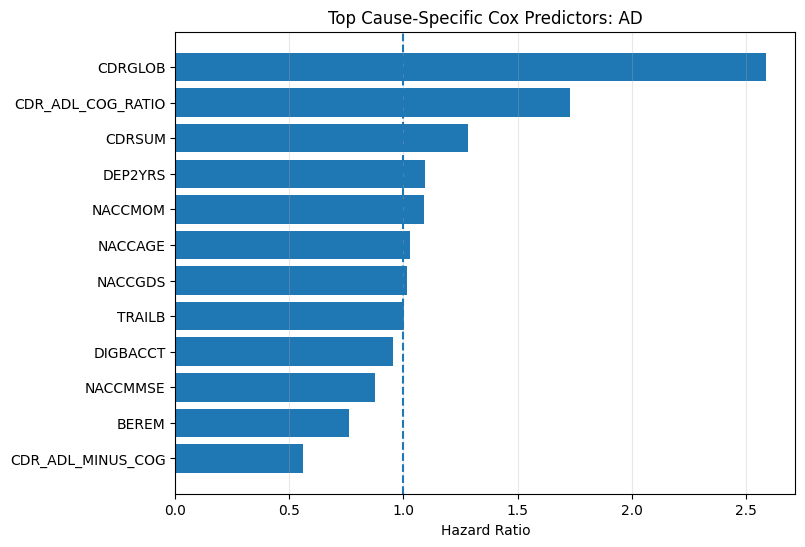

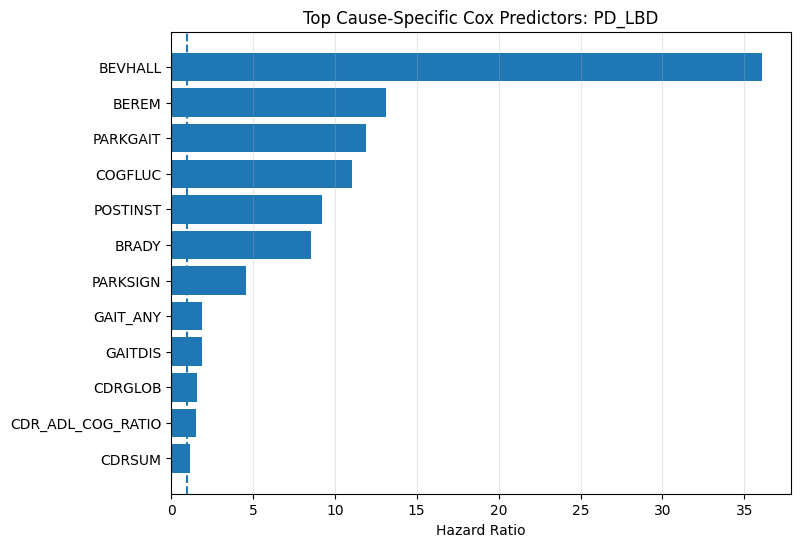

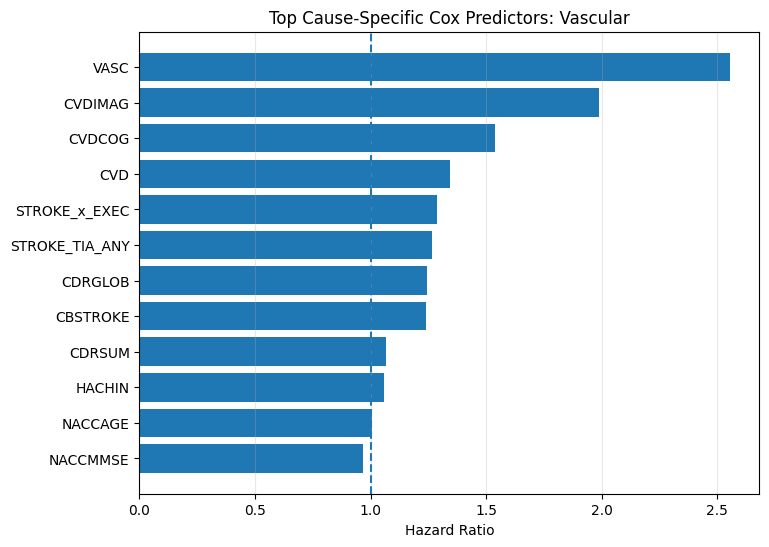

In [31]:
# top HR plots for each etiology

for outcome, cph in cause_models.items():
    hr_table = cph.summary[["exp(coef)", "p"]].copy()
    hr_table = hr_table.rename(columns={"exp(coef)": "hazard_ratio", "p": "p_value"})
    hr_table = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

    plt.figure(figsize=(8, 6))
    plt.barh(hr_table.index.astype(str), hr_table["hazard_ratio"])
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("Hazard Ratio")
    plt.title(f"Top Cause-Specific Cox Predictors: {outcome}")
    plt.grid(True, axis="x", alpha=0.3)
    plt.show()

# CDRSUM vs no-CDRSUM

Tests whether model is just driven by baseline cognitive severity.

In [32]:
# CDRSUM vs no-CDRSUM sensitivity analysis

def prep_for_cox(df, features, duration_col="time_to_event", event_col="event_flag"):
    tmp = df[[duration_col, event_col] + [c for c in features if c in df.columns]].copy()

    for col in tmp.columns:
        if col in [duration_col, event_col]:
            continue

        tmp[col] = pd.to_numeric(tmp[col], errors="coerce")

        if tmp[col].notna().sum() == 0:
            tmp[col] = 0
        else:
            tmp[col] = tmp[col].fillna(tmp[col].median())

    return tmp


base_features_with_cdr = [c for c in ANY_DEMENTIA_FEATURES if c in model_df.columns]
base_features_no_cdr = [f for f in base_features_with_cdr if f != "CDRSUM"]


def fit_compare_model(df, event_name=None):
    tmp = df.copy()

    if event_name is None:
        tmp["event_flag"] = tmp["event_any_dementia"].astype(int)
        model_label = "AnyDementia"
    else:
        tmp["event_flag"] = (tmp["event_type"] == event_name).astype(int)
        model_label = event_name

    df_with = prep_for_cox(tmp, base_features_with_cdr, event_col="event_flag")
    cph_with = CoxPHFitter(penalizer=0.1)
    cph_with.fit(df_with, duration_col="time_to_event", event_col="event_flag")

    df_no = prep_for_cox(tmp, base_features_no_cdr, event_col="event_flag")
    cph_no = CoxPHFitter(penalizer=0.1)
    cph_no.fit(df_no, duration_col="time_to_event", event_col="event_flag")

    return {
        "label": model_label,
        "with_cdr": cph_with,
        "without_cdr": cph_no,
        "df_with": df_with,
        "df_no": df_no
    }


sensitivity_results = {}
for outcome in [None, "AD", "PD_LBD", "Vascular"]:
    res = fit_compare_model(model_df, outcome)
    sensitivity_results[res["label"]] = res

summary_rows = []
for label, res in sensitivity_results.items():
    summary_rows.append({
        "model": label,
        "concordance_with_cdr": res["with_cdr"].concordance_index_,
        "concordance_without_cdr": res["without_cdr"].concordance_index_,
        "partial_AIC_with_cdr": res["with_cdr"].AIC_partial_,
        "partial_AIC_without_cdr": res["without_cdr"].AIC_partial_
    })

sensitivity_summary = pd.DataFrame(summary_rows)
display(sensitivity_summary)

,model,concordance_with_cdr,concordance_without_cdr,partial_AIC_with_cdr,partial_AIC_without_cdr
0,AnyDementia,0.872117,0.867899,84924.373968,85332.593025
1,AD,0.872685,0.868541,74106.567697,74505.774498
2,PD_LBD,0.945048,0.944330,10944.128626,10883.077189
3,Vascular,0.889610,0.889554,4591.049299,4598.926026


# Cross-etiology heatmap

In [33]:
# Cross-etiology factor comparison heatmap

heatmap_models = {
    "AD": sensitivity_results["AD"]["with_cdr"],
    "PD_LBD": sensitivity_results["PD_LBD"]["with_cdr"],
    "Vascular": sensitivity_results["Vascular"]["with_cdr"]
}

predictors_of_interest = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","DEP2YRS","NACCGDS",
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","CVDCOG","CVDIMAG",
    "IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN","HACHIN",
    "POSTINST","VASC_MED_COUNT","GAIT_ANY",
    "STROKDEC","STROKMUL","STROKE_x_EXEC",
    "COGFLUC","BEVHALL","BEREM","PARKSIGN"
]

heatmap_data = pd.DataFrame(index=predictors_of_interest)

for label, model in heatmap_models.items():
    vals = []
    for pred in predictors_of_interest:
        if pred in model.summary.index:
            vals.append(model.summary.loc[pred, "coef"])
        else:
            vals.append(np.nan)
    heatmap_data[label] = vals

display(heatmap_data)

,AD,PD_LBD,Vascular
NACCAGE,0.029609,0.001434,0.006617
SEX,-0.042807,-0.179353,-0.023995
EDUC,0.004712,0.002837,-0.001230
NACCMMSE,-0.132284,-0.026409,-0.033840
CDRSUM,0.250042,0.159145,0.062900
DEP2YRS,0.089859,0.096564,0.046386
NACCGDS,0.017055,0.030757,0.011909
DIABETES,-0.071968,-0.044151,0.060672
HYPERTEN,-0.013689,-0.035636,0.059352
HYPERCHO,0.003664,-0.000341,0.028474


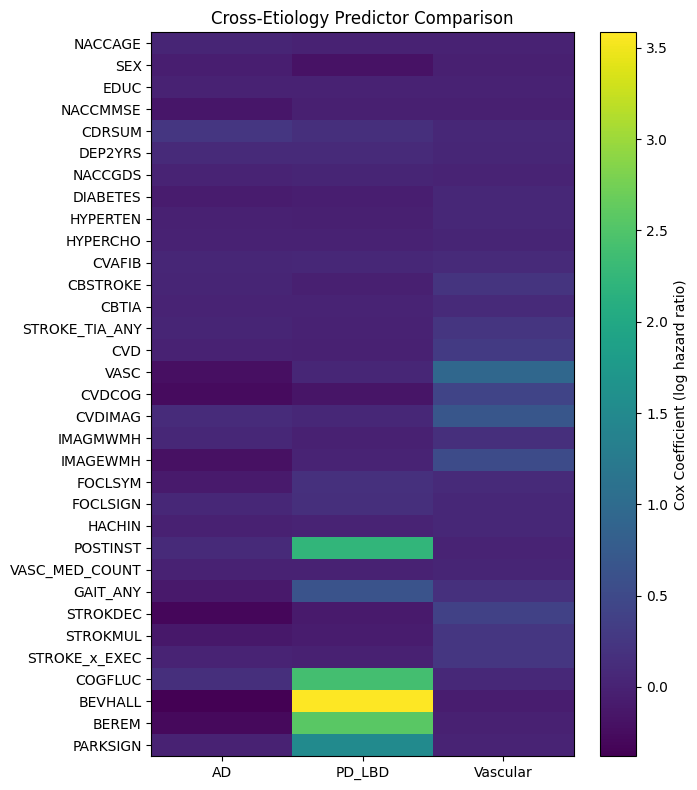

In [34]:
plt.figure(figsize=(7, 8))

plot_data = heatmap_data.copy()

im = plt.imshow(plot_data.values, aspect="auto")
plt.colorbar(im, label="Cox Coefficient (log hazard ratio)")

plt.xticks(range(len(plot_data.columns)), plot_data.columns)
plt.yticks(range(len(plot_data.index)), plot_data.index)
plt.title("Cross-Etiology Predictor Comparison")
plt.tight_layout()
plt.show()

3) vascular burden index

Cell below — Building vascular burden index

In [35]:
# vascular burden index using final E8b-aligned vascular features

vascular_candidates = [
    "CBSTROKE",
    "CBTIA",
    "STROKE_TIA_ANY",
    "DIABETES",
    "DIABET",
    "HYPERTEN",
    "HYPERCHO",
    "CVAFIB",
    "CVD",
    "VASC",
    "CVDCOG",
    "CVDIMAG",
    "IMAGMWMH",
    "IMAGEWMH",
    "FOCLSYM",
    "FOCLSIGN",
    "HACHIN",
    "HACHIN_GE_4",
    "HACHIN_GE_7",
    "POSTINST",
    "VASC_MED_COUNT",
    "GAIT_ANY",
    "STROKDEC",
    "STROKMUL",
    "STROKE_x_EXEC"
]

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("vascular_features:", vascular_features)

vbi_df = model_df.copy()
vbi_df["vascular_target"] = (vbi_df["event_type"] == "Vascular").astype(int)

X_vbi = vbi_df[vascular_features].copy()
y_vbi = vbi_df["vascular_target"].copy()

for col in X_vbi.columns:
    X_vbi[col] = pd.to_numeric(X_vbi[col], errors="coerce")
    if X_vbi[col].notna().sum() == 0:
        X_vbi[col] = 0
    else:
        X_vbi[col] = X_vbi[col].fillna(X_vbi[col].median())

vbi_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=RANDOM_STATE
)
vbi_model.fit(X_vbi, y_vbi)

vbi_df["vascular_burden_index"] = vbi_model.predict_proba(X_vbi)[:, 1]

print(vbi_df["vascular_burden_index"].describe())

vascular_features: ['CBSTROKE', 'CBTIA', 'STROKE_TIA_ANY', 'DIABETES', 'DIABET', 'HYPERTEN', 'HYPERCHO', 'CVAFIB', 'CVD', 'VASC', 'CVDCOG', 'CVDIMAG', 'IMAGMWMH', 'IMAGEWMH', 'FOCLSYM', 'FOCLSIGN', 'HACHIN', 'HACHIN_GE_4', 'HACHIN_GE_7', 'POSTINST', 'VASC_MED_COUNT', 'GAIT_ANY', 'STROKDEC', 'STROKMUL', 'STROKE_x_EXEC']
count    27052.000000
mean         0.375233
std          0.170276
min          0.005074
25%          0.259560
50%          0.350067
75%          0.423212
max          0.999915
Name: vascular_burden_index, dtype: float64


Cell below — Inspect vascular burden weights

In [36]:
# Inspect vascular burden model weights

vbi_coef = pd.DataFrame({
    "feature": X_vbi.columns,
    "coef": vbi_model.coef_[0]
}).sort_values("coef", ascending=False)

display(vbi_coef)

,feature,coef
9,VASC,2.458655
17,HACHIN_GE_4,2.381910
11,CVDIMAG,1.726904
8,CVD,1.649830
13,IMAGEWMH,1.155695
18,HACHIN_GE_7,0.855352
3,DIABETES,0.765640
5,HYPERTEN,0.738659
0,CBSTROKE,0.714423
12,IMAGMWMH,0.688322


Cell below — Merge vascular burden into survival modeling

In [37]:
# adding VBI survival model

model_df = model_df.merge(
    vbi_df[["NACCID", "vascular_burden_index"]],
    on="NACCID",
    how="left"
)

if "vascular_burden_index_x" in model_df.columns:
    model_df["vascular_burden_index"] = model_df["vascular_burden_index_x"]
    drop_cols = [c for c in ["vascular_burden_index_x", "vascular_burden_index_y"] if c in model_df.columns]
    model_df = model_df.drop(columns=drop_cols)

print(model_df[["NACCID", "vascular_burden_index"]].head())

       NACCID  vascular_burden_index
0  NACC000011               0.263079
1  NACC000034               0.361893
2  NACC000067               0.343070
3  NACC000138               0.231006
4  NACC000144               0.725139


Cell below — Refit any-dementia Cox with vascular burden index

In [38]:
# any-dementia cox + vascular burden index

cox_features_plus_vbi = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","DEP2YRS","NACCGDS",
    "STROKE_TIA_ANY","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

cox_vbi_df = model_df[
    ["time_to_event", "event_any_dementia"] + [c for c in cox_features_plus_vbi if c in model_df.columns]
].copy()

for col in cox_vbi_df.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    cox_vbi_df[col] = pd.to_numeric(cox_vbi_df[col], errors="coerce")
    if cox_vbi_df[col].notna().sum() == 0:
        cox_vbi_df[col] = 0
    else:
        cox_vbi_df[col] = cox_vbi_df[col].fillna(cox_vbi_df[col].median())

cox_vbi = CoxPHFitter(penalizer=0.1)
cox_vbi.fit(cox_vbi_df, duration_col="time_to_event", event_col="event_any_dementia")

display(
    cox_vbi.summary[["coef", "exp(coef)", "se(coef)", "p"]]
    .sort_values("p")
    .head(20)
)

,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.469776,1.599636,0.006807,0.000000e+00
NACCMMSE,-0.160708,0.851540,0.005533,1.757055e-185
NACCAGE,0.030719,1.031196,0.001255,2.682998e-132
NACCGDS,0.040298,1.041121,0.004945,3.652848e-16
SEX,-0.164536,0.848287,0.023418,2.124001e-12
DEP2YRS,0.179979,1.197192,0.028075,1.448169e-10
EDUC,0.005180,1.005193,0.001774,3.509302e-03
STROKE_TIA_ANY,0.111926,1.118431,0.046922,1.706163e-02
vascular_burden_index,0.105628,1.111408,0.074268,1.549558e-01


Cell below — Survival curves stratified by vascular burden tertiles

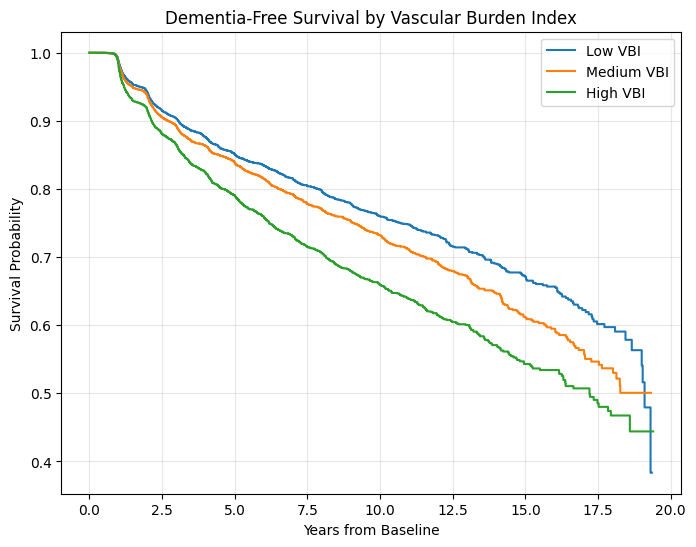

In [39]:
# Kaplan-Meier curves by VBI tertiles

km_vbi_df = model_df[["time_to_event", "event_any_dementia", "vascular_burden_index"]].dropna().copy()
km_vbi_df["vbi_group"] = pd.qcut(
    km_vbi_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for grp in ["Low VBI", "Medium VBI", "High VBI"]:
    tmp = km_vbi_df[km_vbi_df["vbi_group"] == grp]
    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot(ci_show=False)

plt.title("Dementia-Free Survival by Vascular Burden Index")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

# Stratified competing-risk plot

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


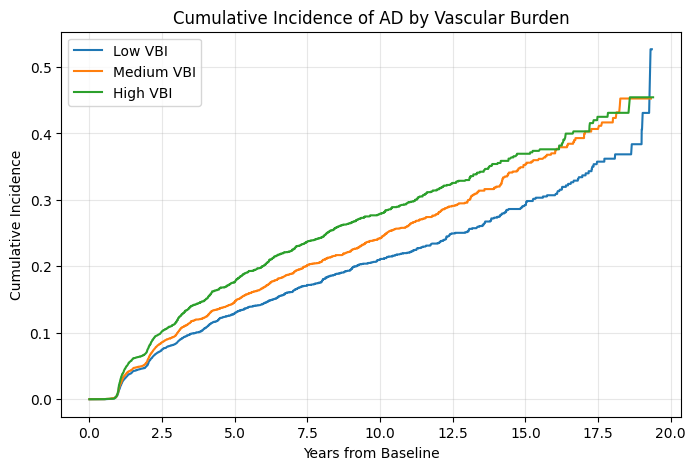

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


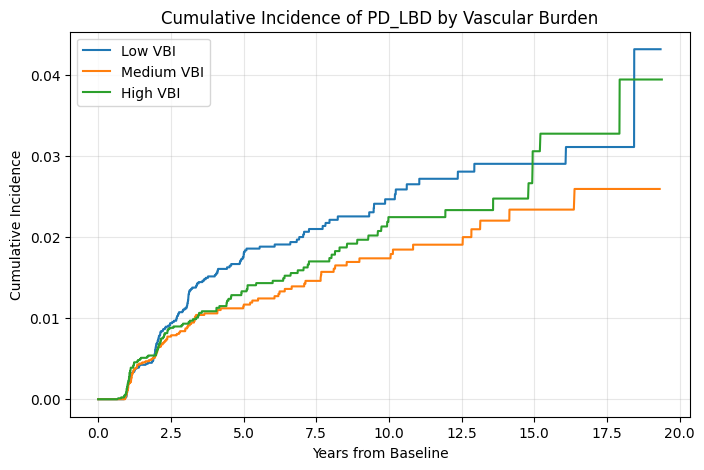

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


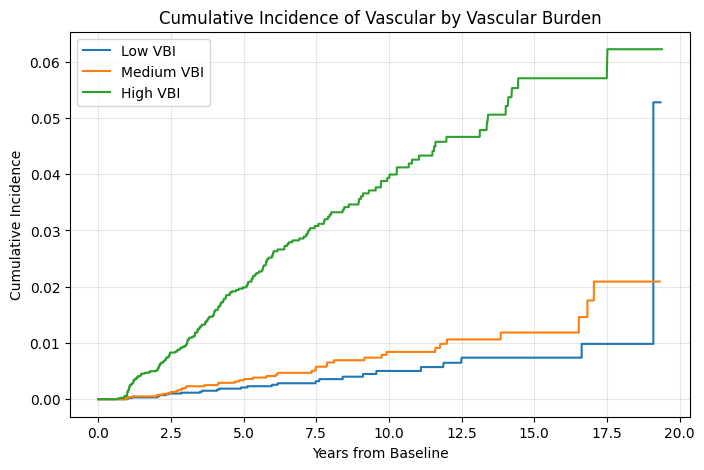

In [40]:
# Stratified competing-risk cumulative incidence by VBI tertile

# Merge VBI into competing-risk dataframe
if "vascular_burden_index" not in cr_df.columns:
    cr_df = cr_df.merge(
        model_df[["NACCID", "vascular_burden_index"]].drop_duplicates(),
        on="NACCID",
        how="left"
    )

cr_df["vbi_group"] = pd.qcut(
    cr_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

for event_name, event_code in event_map.items():
    plt.figure(figsize=(8, 5))

    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        plt.plot(
            ajf.cumulative_density_.index,
            ajf.cumulative_density_.iloc[:, 0],
            label=grp
        )

    plt.title(f"Cumulative Incidence of {event_name} by Vascular Burden")
    plt.xlabel("Years from Baseline")
    plt.ylabel("Cumulative Incidence")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [41]:
milestone_years = [5, 10, 15]
rows = []

for event_name, event_code in event_map.items():
    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        vals = {}
        for yr in milestone_years:
            idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
            vals[f"{yr}y"] = float(ajf.cumulative_density_.iloc[idx, 0])

        rows.append({
            "event": event_name,
            "vbi_group": grp,
            **vals
        })

cif_vbi_table = pd.DataFrame(rows)
display(cif_vbi_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is rand

,event,vbi_group,5y,10y,15y
0,AD,Low VBI,0.129349,0.210593,0.292153
1,AD,Medium VBI,0.146382,0.242347,0.352499
2,AD,High VBI,0.176584,0.279043,0.369429
3,PD_LBD,Low VBI,0.017490,0.024641,0.029009
4,PD_LBD,Medium VBI,0.011431,0.017361,0.023367
5,PD_LBD,High VBI,0.013298,0.022441,0.030563
6,Vascular,Low VBI,0.002089,0.005024,0.007388
7,Vascular,Medium VBI,0.003366,0.008412,0.011857
8,Vascular,High VBI,0.019888,0.039356,0.057052


In [42]:
milestone_years = [5, 10, 15]
rows = []

for event_name, event_code in event_map.items():
    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        vals = {}
        for yr in milestone_years:
            idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
            vals[f"{yr}y"] = float(ajf.cumulative_density_.iloc[idx, 0])

        rows.append({
            "event": event_name,
            "vbi_group": grp,
            **vals
        })

cif_vbi_table = pd.DataFrame(rows)
display(cif_vbi_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is rand

,event,vbi_group,5y,10y,15y
0,AD,Low VBI,0.129347,0.210028,0.292146
1,AD,Medium VBI,0.146381,0.242350,0.352531
2,AD,High VBI,0.176575,0.279035,0.369441
3,PD_LBD,Low VBI,0.017489,0.024641,0.029009
4,PD_LBD,Medium VBI,0.011430,0.017361,0.023366
5,PD_LBD,High VBI,0.013299,0.022442,0.030571
6,Vascular,Low VBI,0.002089,0.005023,0.007387
7,Vascular,Medium VBI,0.003366,0.008412,0.011857
8,Vascular,High VBI,0.019890,0.039358,0.057057


4) Bootstrap uncertainty-aware survival prediction
Cell below — Bootstrap Cox ensemble


In [43]:
# bootstrap ensemble for 5-year risk prediction uncertainty

N_BOOT = 30
PRED_HORIZON_YEARS = 5.0

boot_features = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","DEP2YRS","NACCGDS",
    "STROKE_TIA_ANY","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

boot_df = model_df[
    ["NACCID", "time_to_event", "event_any_dementia"] + [c for c in boot_features if c in model_df.columns]
].copy()

for col in boot_df.columns:
    if col in ["NACCID", "time_to_event", "event_any_dementia"]:
        continue
    boot_df[col] = pd.to_numeric(boot_df[col], errors="coerce")
    if boot_df[col].notna().sum() == 0:
        boot_df[col] = 0
    else:
        boot_df[col] = boot_df[col].fillna(boot_df[col].median())

fit_cols = [c for c in boot_df.columns if c != "NACCID"]
boot_feature_cols = [c for c in fit_cols if c not in ["time_to_event", "event_any_dementia"]]

risk_preds = []

for b in range(N_BOOT):
    sample_idx = np.random.choice(len(boot_df), size=len(boot_df), replace=True)
    boot_sample = boot_df.iloc[sample_idx][fit_cols].copy()

    cph_b = CoxPHFitter(penalizer=0.1)
    cph_b.fit(
        boot_sample,
        duration_col="time_to_event",
        event_col="event_any_dementia"
    )

    surv_funcs = cph_b.predict_survival_function(
        boot_df[boot_feature_cols],
        times=[PRED_HORIZON_YEARS]
    )

    risk_5y = 1.0 - surv_funcs.T.iloc[:, 0].values
    risk_preds.append(risk_5y)

risk_preds = np.vstack(risk_preds)

print("risk_preds shape:", risk_preds.shape)
print("n patients:", len(boot_df))
print("n feature cols:", len(boot_feature_cols))

risk_preds shape: (30, 27052)
n patients: 27052
n feature cols: 12


Cell below — Compute uncertainty + confidence

In [44]:
# uncertainty / confidence scores

uncertainty_df = boot_df[["NACCID", "time_to_event", "event_any_dementia"]].copy()
uncertainty_df["risk_5y_mean"] = risk_preds.mean(axis=0)
uncertainty_df["risk_5y_std"]  = risk_preds.std(axis=0)
uncertainty_df["risk_5y_p10"]  = np.percentile(risk_preds, 10, axis=0)
uncertainty_df["risk_5y_p90"]  = np.percentile(risk_preds, 90, axis=0)

# simple confidence score
max_std = uncertainty_df["risk_5y_std"].max()
uncertainty_df["confidence_score"] = 1 - (uncertainty_df["risk_5y_std"] / max_std)
uncertainty_df["confidence_score"] = uncertainty_df["confidence_score"].clip(0, 1)

display(uncertainty_df.head())
display(uncertainty_df.describe())

,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
0,NACC000011,3.296372,0,0.076114,0.001860,0.073591,0.078608,0.976331
1,NACC000034,5.848049,1,0.146430,0.003303,0.142919,0.150753,0.957979
2,NACC000067,2.088980,0,0.200817,0.027640,0.165965,0.230168,0.648357
3,NACC000138,1.043121,0,0.056679,0.001748,0.054345,0.058934,0.977757
4,NACC000144,8.487337,0,0.178034,0.015507,0.158374,0.194403,0.802716


,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
count,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000
mean,5.117712,0.179321,0.180360,0.008039,0.170829,0.191104,0.897723
std,4.214639,0.383628,0.151857,0.008940,0.144086,0.161642,0.113742
min,0.109514,0.000000,0.017576,0.000000,0.016306,0.018548,0.000000
25%,1.938398,0.000000,0.092662,0.002854,0.088789,0.096863,0.883678
50%,3.786448,0.000000,0.127338,0.004741,0.121222,0.133847,0.939689
75%,7.124572,0.000000,0.201776,0.009143,0.190152,0.214068,0.963686
max,19.392197,1.000000,1.000000,0.078602,1.000000,1.000000,1.000000


Cell below — Scatter plot: risk vs uncertainty

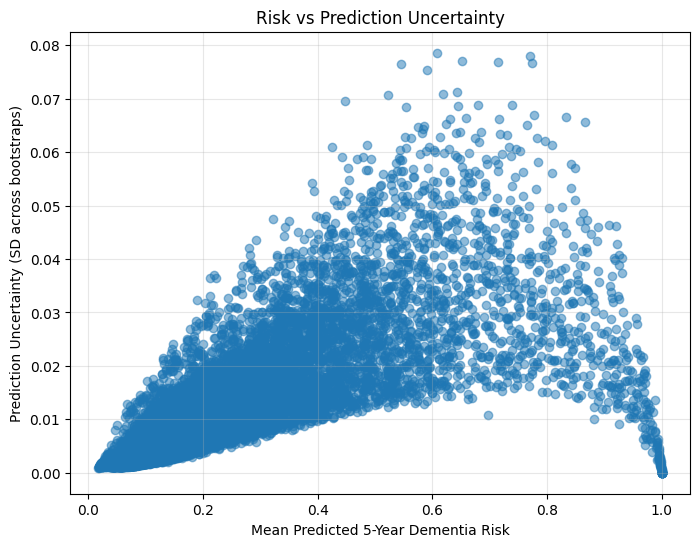

In [45]:
# risk vs uncertainty plot

plt.figure(figsize=(8, 6))
plt.scatter(
    uncertainty_df["risk_5y_mean"],
    uncertainty_df["risk_5y_std"],
    alpha=0.5
)
plt.xlabel("Mean Predicted 5-Year Dementia Risk")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Risk vs Prediction Uncertainty")
plt.grid(True, alpha=0.3)
plt.show()

Cell below — Identify high-uncertainty cases

In [46]:
# flag high-uncertainty cases

uncert_thresh = uncertainty_df["risk_5y_std"].quantile(0.80)
uncertainty_df["high_uncertainty"] = (uncertainty_df["risk_5y_std"] >= uncert_thresh).astype(int)

print("High-uncertainty threshold:", uncert_thresh)
print(uncertainty_df["high_uncertainty"].value_counts())

display(
    uncertainty_df.sort_values("risk_5y_std", ascending=False).head(15)
)

High-uncertainty threshold: 0.011047788226084885
high_uncertainty
0    21641
1     5411
Name: count, dtype: int64


,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score,high_uncertainty
8244,NACC307329,1.111567,1,0.607693,0.078602,0.519742,0.720932,0.000000,1
15201,NACC561917,6.518823,0,0.770272,0.078071,0.677521,0.880395,0.006749,1
8307,NACC309605,8.640657,0,0.651490,0.076964,0.563910,0.754788,0.020834,1
14979,NACC553391,0.966461,1,0.713847,0.076943,0.636948,0.817322,0.021109,1
11992,NACC444257,1.075975,1,0.772911,0.076705,0.686213,0.882507,0.024128,1
58,NACC001959,3.485284,0,0.545023,0.076569,0.447327,0.638836,0.025867,1
7776,NACC289818,1.155373,1,0.590262,0.075397,0.512709,0.698059,0.040767,1
16754,NACC618927,0.999316,1,0.643681,0.071278,0.561413,0.743742,0.093179,1
7511,NACC280530,1.927447,1,0.619375,0.070850,0.536724,0.723413,0.098617,1
8060,NACC300648,5.002053,0,0.522062,0.070673,0.456217,0.602111,0.100875,1


5) Uncertain-case phenotype analysis
Cell below — Merge uncertainty back to clinical variables

In [47]:
# merge uncertainty back for phenotype analysis

analysis_df = model_df.merge(
    uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score", "high_uncertainty"]],
    on="NACCID",
    how="left"
)

print(analysis_df.shape)

(27052, 88)


Cell below — Compare high- vs low-uncertainty groups

In [48]:
# phenotype comparison: high vs low uncertainty 

compare_vars = [
    "NACCAGE","EDUC","NACCMMSE","CDRSUM","NACCGDS",
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

rows = []
for col in compare_vars:
    if col not in analysis_df.columns:
        continue

    tmp0 = analysis_df.loc[analysis_df["high_uncertainty"] == 0, col]
    tmp1 = analysis_df.loc[analysis_df["high_uncertainty"] == 1, col]

    rows.append({
        "variable": col,
        "low_uncert_mean": pd.to_numeric(tmp0, errors="coerce").mean(),
        "high_uncert_mean": pd.to_numeric(tmp1, errors="coerce").mean(),
        "difference": pd.to_numeric(tmp1, errors="coerce").mean() - pd.to_numeric(tmp0, errors="coerce").mean()
    })

uncert_compare = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(uncert_compare)

,variable,low_uncert_mean,high_uncert_mean,difference
0,NACCAGE,69.885634,74.798743,4.913110
4,NACCGDS,1.352997,3.204636,1.851639
3,CDRSUM,0.248718,1.708002,1.459285
14,HACHIN,0.597460,1.501044,0.903584
1,EDUC,15.940483,16.737017,0.796534
15,VASC_MED_COUNT,1.260154,1.696174,0.436020
9,CBSTROKE,0.022511,0.189707,0.167196
6,HYPERTEN,0.485490,0.642495,0.157005
11,STROKE_TIA_ANY,0.035858,0.187396,0.151538
10,CBTIA,0.042214,0.176236,0.134022


Cell below — Event-type breakdown inside high-uncertainty cases

In [49]:
# finding what types of events appear in high-uncertainty cases

event_uncert_table = pd.crosstab(
    analysis_df["event_type"],
    analysis_df["high_uncertainty"],
    normalize="columns"
)

display(event_uncert_table)

high_uncertainty,0,1
event_type,,
AD,0.100827,0.376271
Censored,0.885957,0.559601
PD_LBD,0.007116,0.040658
Vascular,0.006100,0.023471


Using Cox model: cox_vbi


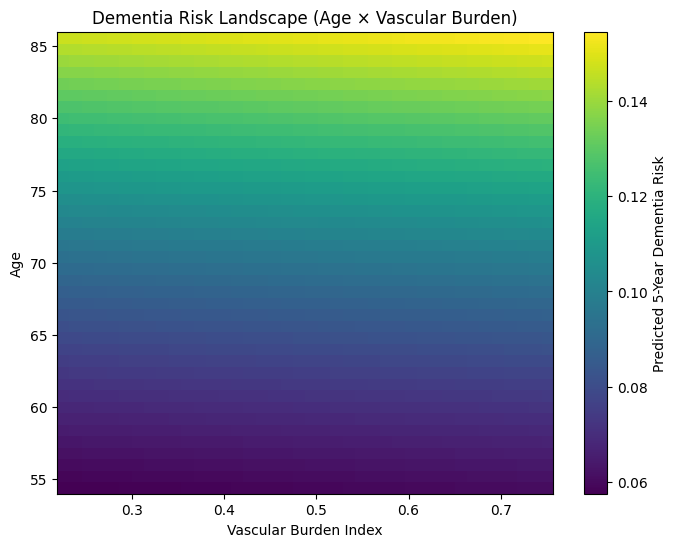

In [50]:
# Dementia Risk Landscape: Age x Vascular Burden

# Identifying the Cox model with vascular burden
main_cph = None
for name in ["cox_vbi", "cph_vbi", "cox_ph", "cox_model"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find the Cox model with vascular_burden_index")

# Columns used by the Cox model
model_cols = list(main_cph.params_.index)

reference = {}
for col in model_cols:
    if col in analysis_df.columns:
        reference[col] = analysis_df[col].median()
    else:
        reference[col] = 0

# using most common value for sex
if "SEX" in analysis_df.columns:
    reference["SEX"] = analysis_df["SEX"].mode()[0]

# Grid ranges
age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

# Build prediction grid
grid_rows = []

for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = age
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = vbi
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[model_cols]

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# Predict 5-year risk
surv = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y = 1 - surv.T.iloc[:, 0].values

risk_matrix = risk_5y.reshape(len(age_grid), len(vbi_grid))

plt.figure(figsize=(8,6))

im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[
        vbi_grid.min(),
        vbi_grid.max(),
        age_grid.min(),
        age_grid.max()
    ]
)

plt.colorbar(im, label="Predicted 5-Year Dementia Risk")

plt.xlabel("Vascular Burden Index")
plt.ylabel("Age")
plt.title("Dementia Risk Landscape (Age × Vascular Burden)")

plt.show()

6)  diagreement analysis hook

In [51]:
# classifier vs observed outcome disordance
# compares classifier predictions to observed event_type.

clf_preds = pd.read_csv("../output/classifier_predictions.csv")

if "clf_preds" in globals():
    dis_df = analysis_df.copy()

    dis_df = dis_df.merge(clf_preds[["NACCID", "predicted_class"]], on="NACCID", how="left")

    dis_df["predicted_class_norm"] = dis_df["predicted_class"].replace({
        "NoDementia_Hy": "Censored",
        "NoDementia_5y": "Censored"
    })

    dis_df["model_disagreement"] = (
        dis_df["predicted_class_norm"].notna() &
        (dis_df["predicted_class_norm"] != dis_df["event_type"])
    ).astype(int)

    print(dis_df["model_disagreement"].value_counts(dropna=False))

    display(
        pd.crosstab(dis_df["event_type"], dis_df["model_disagreement"], normalize="columns")
    )

    display(
        dis_df.loc[dis_df["model_disagreement"] == 1,
                   ["NACCID", "event_type", "predicted_class", "risk_5y_mean", "risk_5y_std", "confidence_score"]]
        .head(20)
    )
else:
    print("clf_preds not found. Skipping disagreement analysis.")

model_disagreement
0    26487
1      565
Name: count, dtype: int64


model_disagreement,0,1
event_type,,
AD,0.146374,0.603540
Censored,0.832484,0.267257
PD_LBD,0.012836,0.060177
Vascular,0.008306,0.069027


,NACCID,event_type,predicted_class,risk_5y_mean,risk_5y_std,confidence_score
52,NACC001707,AD,NoDementia_Hy,0.260821,0.022860,0.709172
166,NACC005498,AD,NoDementia_Hy,0.136464,0.003305,0.957953
222,NACC007474,AD,NoDementia_Hy,0.163804,0.004323,0.945002
320,NACC011190,AD,NoDementia_Hy,0.075432,0.002036,0.974093
361,NACC012829,AD,NoDementia_Hy,0.201836,0.007137,0.909198
447,NACC016700,Censored,AD,0.236284,0.006635,0.915584
471,NACC017560,Censored,AD,0.153136,0.002735,0.965201
478,NACC017883,AD,NoDementia_Hy,0.073121,0.001975,0.974873
503,NACC018917,Vascular,NoDementia_Hy,0.130108,0.003019,0.961593
524,NACC019767,Censored,AD,0.299258,0.025170,0.679773


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Retrieving cause-specific models
def get_cause_models():
    models = {}

    if "cause_models" in globals():
        if isinstance(cause_models, dict):
            models = cause_models.copy()

    if "AD" not in models:
        if "cph_AD" in globals():
            models["AD"] = cph_AD
    if "PD_LBD" not in models:
        if "cph_PD" in globals():
            models["PD_LBD"] = cph_PD
        elif "cph_PD_LBD" in globals():
            models["PD_LBD"] = cph_PD_LBD
    if "Vascular" not in models:
        if "cph_VASC" in globals():
            models["Vascular"] = cph_VASC
        elif "cph_Vascular" in globals():
            models["Vascular"] = cph_Vascular

    return models

cause_model_map = get_cause_models()
print("Available cause-specific models:", list(cause_model_map.keys()))

Available cause-specific models: ['AD', 'PD_LBD', 'Vascular']


Step 1 — Etiology-specific risk curves

This produces the figure showing projected AD vs PD/LBD vs vascular risk over time.


In [53]:
# Step 1: Etiology-specific risk curves

times = np.linspace(0.5, 20, 120)

# choosing source dataframe for prediction
if "model_df" in globals():
    pred_df_base = model_df.copy()
elif "analysis_df" in globals():
    pred_df_base = analysis_df.copy()
else:
    raise ValueError("Neither model_df nor analysis_df is available.")

risk_curve_summary = {}

for label, model in cause_model_map.items():
    model_cols = list(model.params_.index)

    pred_df = pred_df_base.copy()

    for col in model_cols:
        if col not in pred_df.columns:
            pred_df[col] = 0

    X_pred = pred_df[model_cols].copy()

    for col in X_pred.columns:
        X_pred[col] = pd.to_numeric(X_pred[col], errors="coerce").fillna(0)

    surv = model.predict_survival_function(X_pred, times=times)
    # mean cause-specific event probability over time
    mean_risk = (1 - surv).mean(axis=1)

    risk_curve_summary[label] = pd.Series(mean_risk.values, index=times)

risk_curve_df = pd.DataFrame(risk_curve_summary)
display(risk_curve_df.head())

,AD,PD_LBD,Vascular
0.500000,0.001328,0.000000,0.000000
0.663866,0.008211,0.000000,0.000062
0.827731,0.019993,0.000139,0.000124
0.991597,0.130757,0.000663,0.000504
1.155462,0.273473,0.001095,0.001799


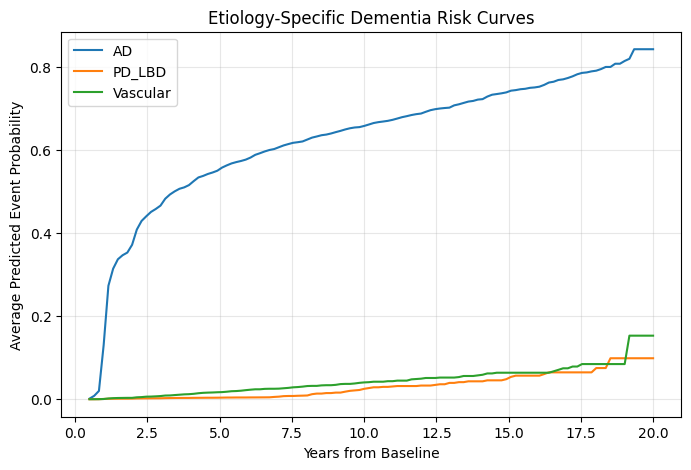

In [54]:
plt.figure(figsize=(8, 5))

for label in ["AD", "PD_LBD", "Vascular"]:
    if label in risk_curve_df.columns:
        plt.plot(risk_curve_df.index, risk_curve_df[label], label=label)

plt.xlabel("Years from Baseline")
plt.ylabel("Average Predicted Event Probability")
plt.title("Etiology-Specific Dementia Risk Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [55]:
milestone_years = [5, 10, 15]

etiology_risk_table = pd.DataFrame(index=milestone_years)

for label in risk_curve_df.columns:
    etiology_risk_table[label] = [
        float(risk_curve_df[label].iloc[np.argmin(np.abs(risk_curve_df.index - yr))])
        for yr in milestone_years
    ]

etiology_risk_table.index.name = "Years"
display(etiology_risk_table)

,AD,PD_LBD,Vascular
Years,,,
5,0.550741,0.003689,0.016789
10,0.658639,0.025086,0.040520
15,0.739491,0.048280,0.063874


Step 2 — Risk stratification survival curves


In [56]:
# Step 2: Risk stratification groups

if "analysis_df" not in globals():
    if "model_df" in globals() and "uncertainty_df" in globals():
        analysis_df = model_df.merge(
            uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score"]],
            on="NACCID",
            how="left"
        )
    else:
        raise ValueError("Need analysis_df or both model_df and uncertainty_df.")

# creaing risk groups using tertiles
analysis_df["risk_group_3"] = pd.qcut(
    analysis_df["risk_5y_mean"],
    q=3,
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(analysis_df["risk_group_3"].value_counts(dropna=False))

risk_group_3
Low Risk       9018
Medium Risk    9017
High Risk      9017
Name: count, dtype: int64


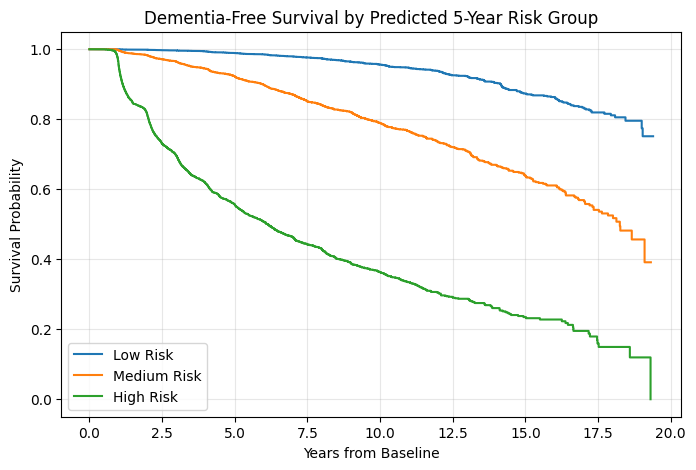

In [57]:
plt.figure(figsize=(8, 5))
kmf = KaplanMeierFitter()

for grp in ["Low Risk", "Medium Risk", "High Risk"]:
    tmp = analysis_df[analysis_df["risk_group_3"] == grp].copy()

    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Dementia-Free Survival by Predicted 5-Year Risk Group")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

In [58]:
risk_group_summary = analysis_df.groupby("risk_group_3").agg(
    n=("NACCID", "count"),
    mean_predicted_5y_risk=("risk_5y_mean", "mean"),
    observed_event_rate=("event_any_dementia", "mean"),
    mean_followup=("time_to_event", "mean")
)

display(risk_group_summary)

C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\1494596913.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  risk_group_summary = analysis_df.groupby("risk_group_3").agg(


,n,mean_predicted_5y_risk,observed_event_rate,mean_followup
risk_group_3,,,,
Low Risk,9018,0.079621,0.033599,6.370614
Medium Risk,9017,0.129777,0.114229,5.383982
High Risk,9017,0.331692,0.390152,3.598401


Step 3 — Explaining uncertainty

creating plots showing who becomes uncertain.

In [59]:
# Step 3: Uncertainty explanation

needed_cols = ["risk_5y_std", "confidence_score"]
for c in needed_cols:
    if c not in analysis_df.columns:
        raise ValueError(f"{c} not found in analysis_df")

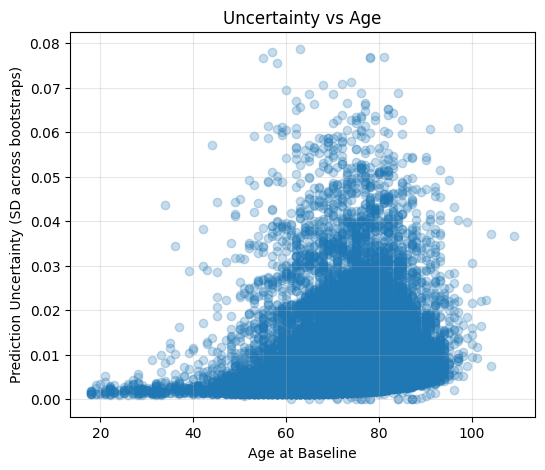

In [60]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["NACCAGE"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("Age at Baseline")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Age")
plt.grid(True, alpha=0.3)
plt.show()

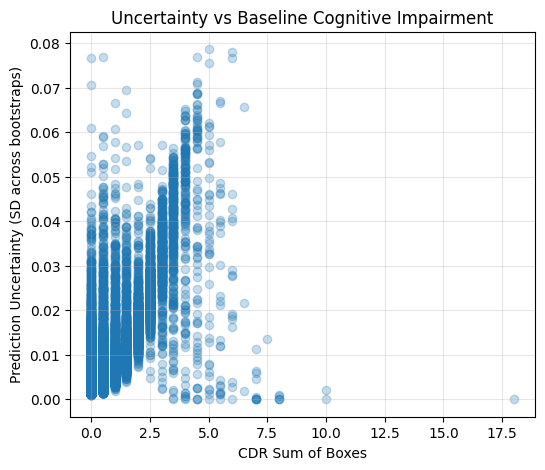

In [61]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["CDRSUM"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("CDR Sum of Boxes")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Baseline Cognitive Impairment")
plt.grid(True, alpha=0.3)
plt.show()

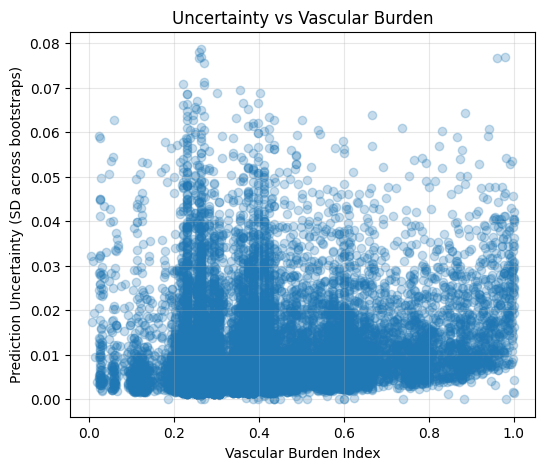

In [62]:
if "vascular_burden_index" in analysis_df.columns:
    plt.figure(figsize=(6, 5))
    plt.scatter(
        analysis_df["vascular_burden_index"],
        analysis_df["risk_5y_std"],
        alpha=0.25
    )
    plt.xlabel("Vascular Burden Index")
    plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
    plt.title("Uncertainty vs Vascular Burden")
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("vascular_burden_index not found in analysis_df")

In [63]:
def make_binned_summary(df, xcol, ycol="risk_5y_std", bins=5):
    tmp = df[[xcol, ycol]].dropna().copy()
    tmp["bin"] = pd.qcut(tmp[xcol], q=bins, duplicates="drop")
    out = tmp.groupby("bin").agg(
        n=(xcol, "count"),
        x_mean=(xcol, "mean"),
        y_mean=(ycol, "mean")
    )
    return out

display(make_binned_summary(analysis_df, "NACCAGE"))
display(make_binned_summary(analysis_df, "CDRSUM"))

if "vascular_burden_index" in analysis_df.columns:
    display(make_binned_summary(analysis_df, "vascular_burden_index"))

C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(17.999, 64.0]",6049,57.403372,0.005900
"(64.0, 69.0]",5397,67.047619,0.006473
"(69.0, 74.0]",5814,71.936877,0.007595
"(74.0, 79.0]",4730,76.849471,0.009718
"(79.0, 109.0]",5062,84.216318,0.011207


C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(-0.001, 0.5]",20417,0.105525,0.005120
"(0.5, 1.0]",2295,1.000000,0.008941
"(1.0, 18.0]",4340,2.344470,0.021294


C:\Users\branjan\AppData\Local\Temp\ipykernel_32684\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(0.00407, 0.25]",5582,0.212133,0.006881
"(0.25, 0.283]",5521,0.263968,0.006186
"(0.283, 0.386]",5376,0.342646,0.007386
"(0.386, 0.461]",5198,0.411761,0.007700
"(0.461, 1.0]",5375,0.656168,0.012127


Step 4 — Age × vascular burden risk heatmap

In [64]:
# Step 4: Age x vascular burden risk landscape

# detecting main Cox model
main_cph = None
for name in ["cph", "cox_model", "cox_vbi", "cph_any"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using main Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find main Cox model. Rename main_cph manually.")

main_model_cols = list(main_cph.params_.index)

reference = {}
for col in main_model_cols:
    if col in analysis_df.columns:
        vals = pd.to_numeric(analysis_df[col], errors="coerce")
        if vals.notna().sum() > 0:
            reference[col] = float(vals.median())
        else:
            reference[col] = 0.0
    else:
        reference[col] = 0.0

if "SEX" in analysis_df.columns and "SEX" in reference:
    sex_mode = analysis_df["SEX"].mode()
    if len(sex_mode) > 0:
        reference["SEX"] = float(sex_mode.iloc[0])

age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

if "vascular_burden_index" not in analysis_df.columns:
    raise ValueError("vascular_burden_index not found in analysis_df")

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

grid_rows = []
for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = float(age)
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = float(vbi)
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[main_model_cols].copy()

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# predict 5-year risk
surv_grid = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y_grid = 1 - surv_grid.T.iloc[:, 0].values

risk_matrix = risk_5y_grid.reshape(len(age_grid), len(vbi_grid))

Using main Cox model: cph


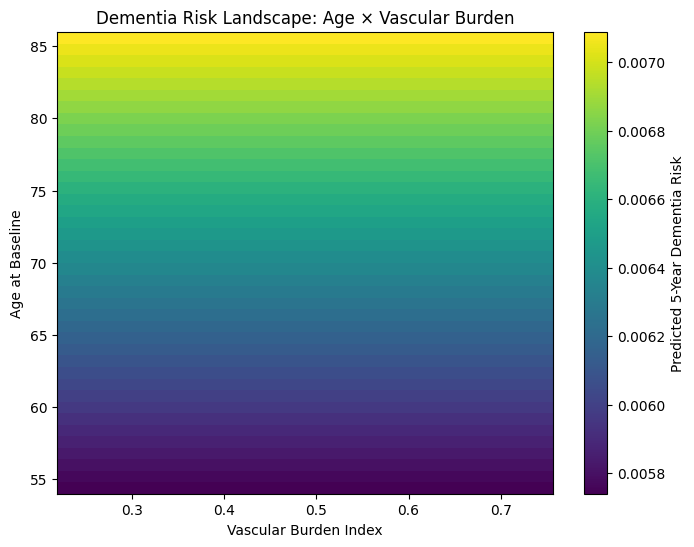

In [65]:
plt.figure(figsize=(8, 6))
im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[vbi_grid.min(), vbi_grid.max(), age_grid.min(), age_grid.max()]
)
plt.colorbar(im, label="Predicted 5-Year Dementia Risk")
plt.xlabel("Vascular Burden Index")
plt.ylabel("Age at Baseline")
plt.title("Dementia Risk Landscape: Age × Vascular Burden")
plt.show()

In [66]:
etiology_risk_table.to_csv("etiology_risk_table.csv")
risk_group_summary.to_csv("risk_group_summary.csv")

if "risk_curve_df" in globals():
    risk_curve_df.to_csv("etiology_risk_curves_full.csv")

print("Saved CSV outputs.")

Saved CSV outputs.
